In [1]:
pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    classification_report,
    confusion_matrix
)

import joblib
import warnings

warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("shopping.csv")

df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [4]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (12330, 18)

Column names:
['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Month', 'OperatingSystems', 'Browser', 'Region', 'TrafficType', 'VisitorType', 'Weekend', 'Revenue']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   P

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Revenue
False    10422
True      1908
Name: count, dtype: int64

Revenue distribution (%):
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


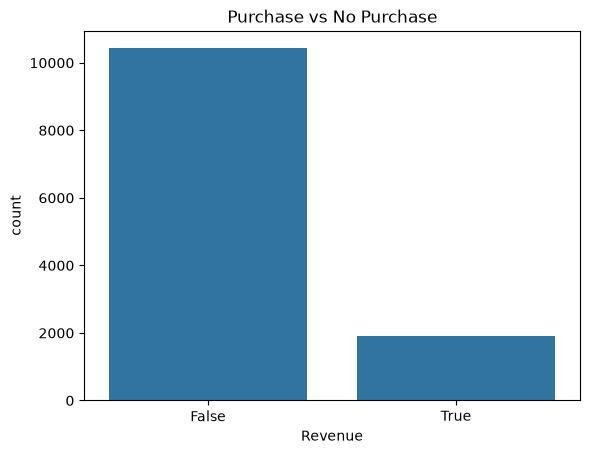

In [5]:
print(df["Revenue"].value_counts())

print("\nRevenue distribution (%):")
print(df["Revenue"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Revenue")
plt.title("Purchase vs No Purchase")
plt.show()

In [6]:
print("Dataset shape:", df.shape)

print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nNumerical summary:")
display(df.describe().T)

print("\nCategorical summary:")
display(df.describe(include="object").T)

Dataset shape: (12330, 18)

Data types:


,Data Type
Administrative,int64
Administrative_Duration,float64
Informational,int64
Informational_Duration,float64
ProductRelated,int64
ProductRelated_Duration,float64
BounceRates,float64
ExitRates,float64
PageValues,float64
SpecialDay,float64



Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000



Categorical summary:


,count,unique,top,freq
Month,12330,10,May,3364
VisitorType,12330,3,Returning_Visitor,10551


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 125


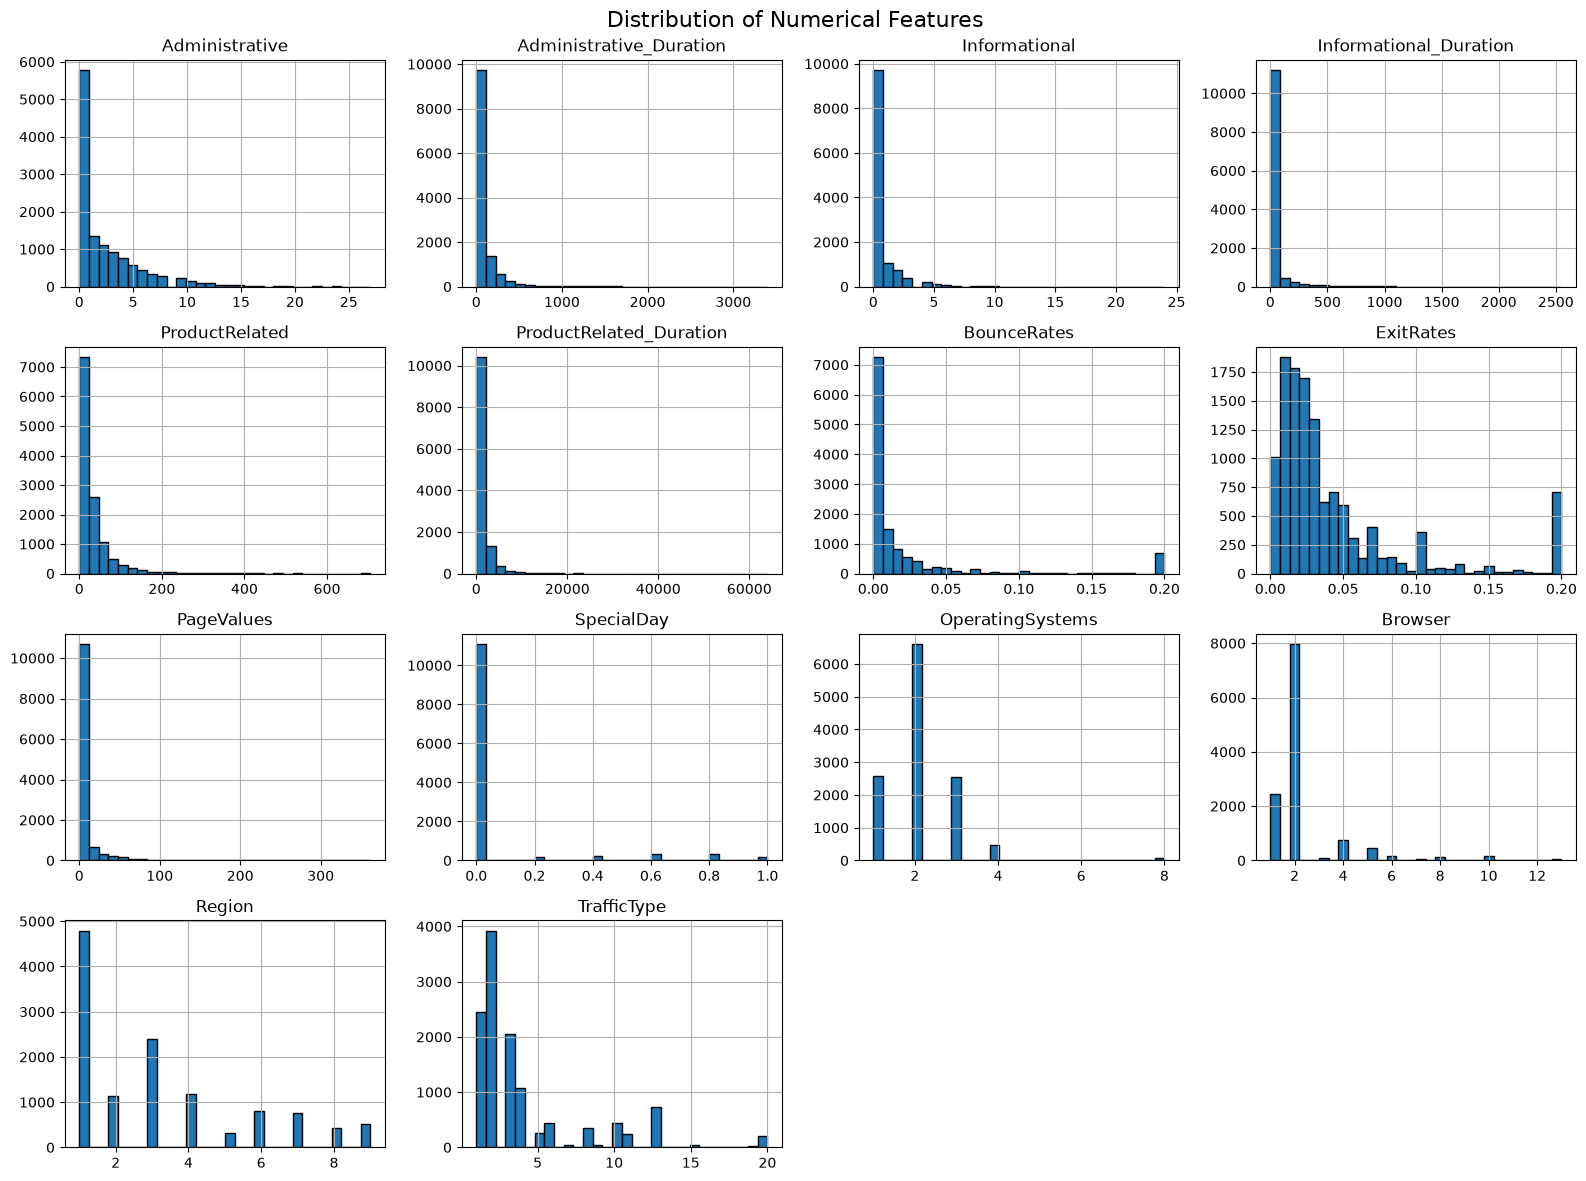

In [8]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].hist(
    figsize=(16, 12),
    bins=30,
    edgecolor="black"
)

plt.suptitle("Distribution of Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

In [9]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.drop("Revenue", errors="ignore")

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].value_counts().head(15))


Month:
Month
May     3364
Nov     2998
Mar     1907
Dec     1727
Oct      549
Sep      448
Aug      433
Jul      432
June     288
Feb      184
Name: count, dtype: int64

VisitorType:
VisitorType
Returning_Visitor    10551
New_Visitor           1694
Other                   85
Name: count, dtype: int64

Weekend:
Weekend
False    9462
True     2868
Name: count, dtype: int64


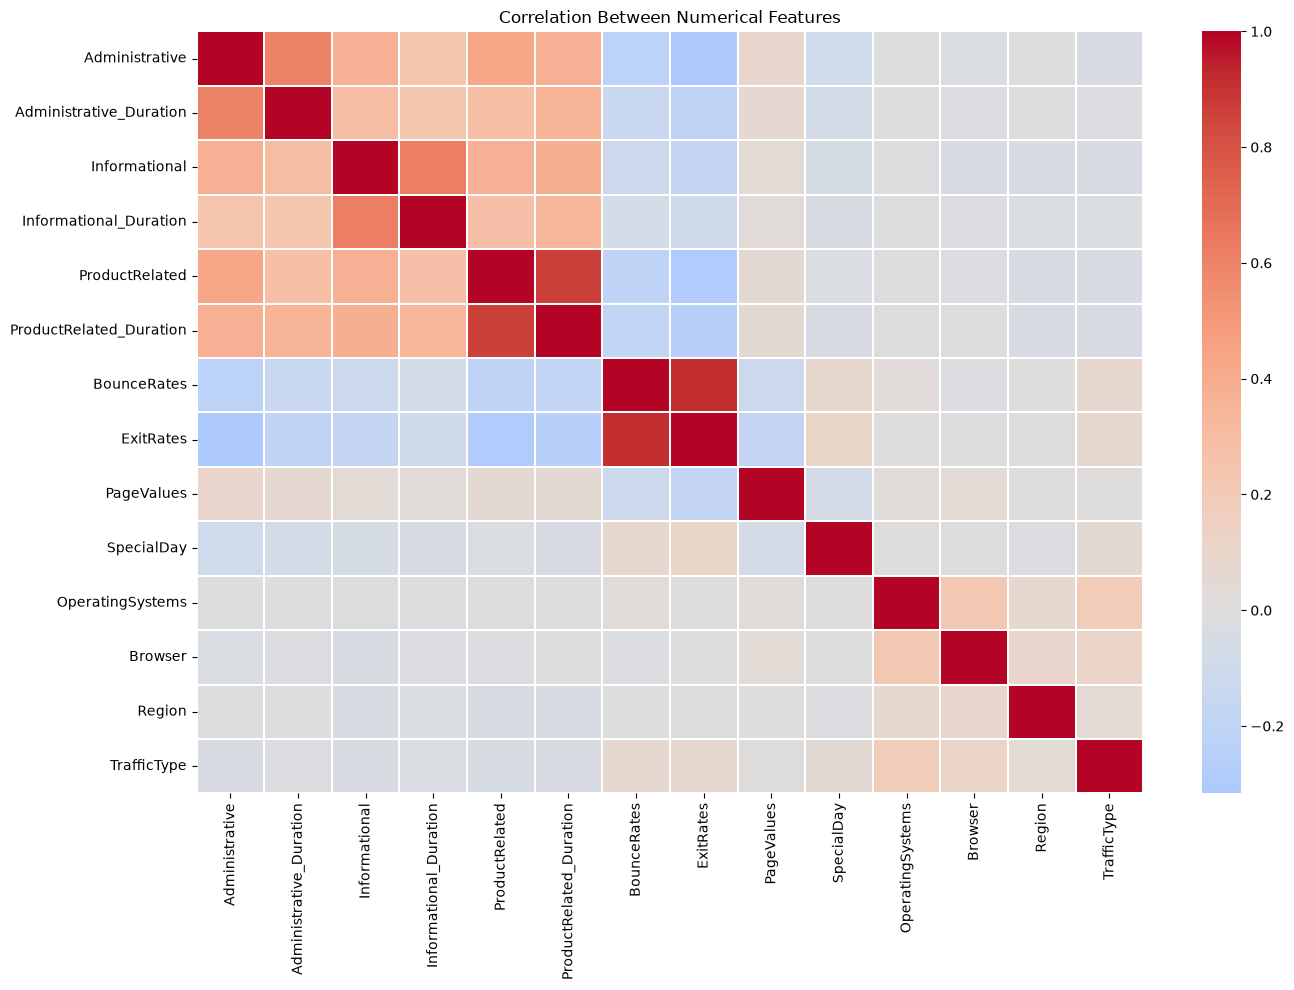

In [10]:
plt.figure(figsize=(14, 10))

correlation = df.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


In [11]:
# Target variable
y = df["Revenue"].astype(int)

# Input features
X = df.drop(columns=["Revenue"])

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget classes:")
print(y.value_counts())

Feature matrix shape: (12330, 17)
Target shape: (12330,)

Target classes:
Revenue
0    10422
1     1908
Name: count, dtype: int64


In [12]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("\nCategorical features:", categorical_features)

print("\nTotal features:", len(numeric_features) + len(categorical_features))

Numerical features: ['Administrative', 'Administrative_Duration', 'Informational', 'Informational_Duration', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'OperatingSystems', 'Browser', 'Region', 'TrafficType']

Categorical features: ['Month', 'VisitorType', 'Weekend']

Total features: 17


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training samples: 9864
Testing samples: 2466

Training target distribution:
Revenue
0    0.845296
1    0.154704
Name: proportion, dtype: float64

Testing target distribution:
Revenue
0    0.845093
1    0.154907
Name: proportion, dtype: float64


In [14]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [15]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "K-Nearest Neighbors": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gaussian Naive Bayes": GaussianNB(),

    "Support Vector Machine": SVC(
        probability=True,
        class_weight="balanced",
        random_state=42
    )
}

print("Models to train:")
for name in models:
    print("-", name)

Models to train:
- Logistic Regression
- Decision Tree
- K-Nearest Neighbors
- Gaussian Naive Bayes
- Support Vector Machine


In [16]:
results = []
trained_models = {}

for name, classifier in models.items():
    print(f"Training {name}...")

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    # Predictions
    y_pred = pipeline.predict(X_test)
    y_prob = pipeline.predict_proba(X_test)[:, 1]

    # Evaluation metrics
    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, y_pred)
    }

    results.append(metrics)
    trained_models[name] = pipeline

print("\nAll models trained successfully.")

Training Logistic Regression...
Training Decision Tree...
Training K-Nearest Neighbors...
Training Gaussian Naive Bayes...
Training Support Vector Machine...

All models trained successfully.


In [17]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "Accuracy": "{:.4f}",
        "AUC": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1 Score": "{:.4f}",
        "MCC": "{:.4f}"
    })
)

,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Support Vector Machine,0.8560,0.8856,0.5258,0.7199,0.6077,0.5319
1,Logistic Regression,0.8500,0.8962,0.5107,0.7487,0.6072,0.5330
2,Decision Tree,0.8512,0.7014,0.5211,0.4843,0.5020,0.4151
3,K-Nearest Neighbors,0.8731,0.7818,0.6456,0.4005,0.4943,0.4422
4,Gaussian Naive Bayes,0.6736,0.7932,0.2937,0.7880,0.4279,0.3234


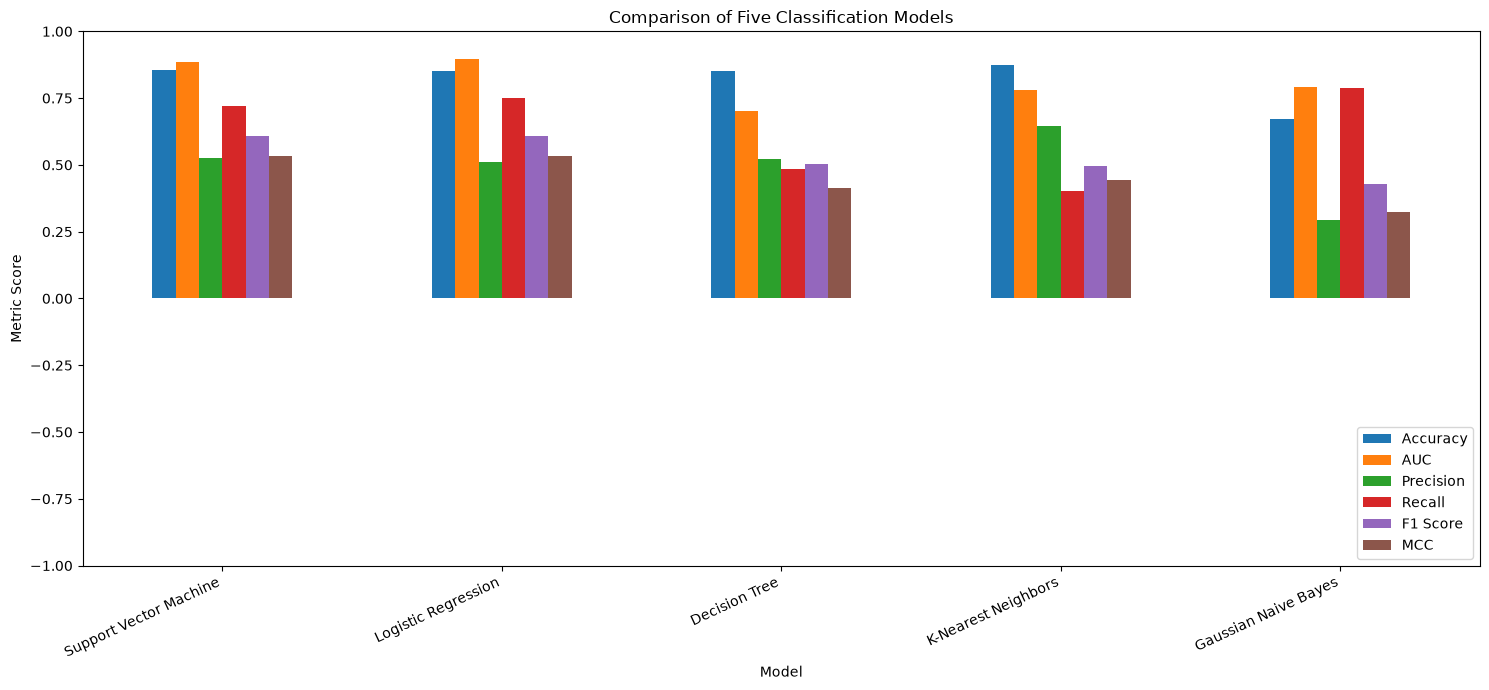

In [18]:
metric_columns = [
    "Accuracy", "AUC", "Precision",
    "Recall", "F1 Score", "MCC"
]

results_df.set_index("Model")[metric_columns].plot(
    kind="bar",
    figsize=(15, 7)
)

plt.title("Comparison of Five Classification Models")
plt.ylabel("Metric Score")
plt.ylim(-1, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

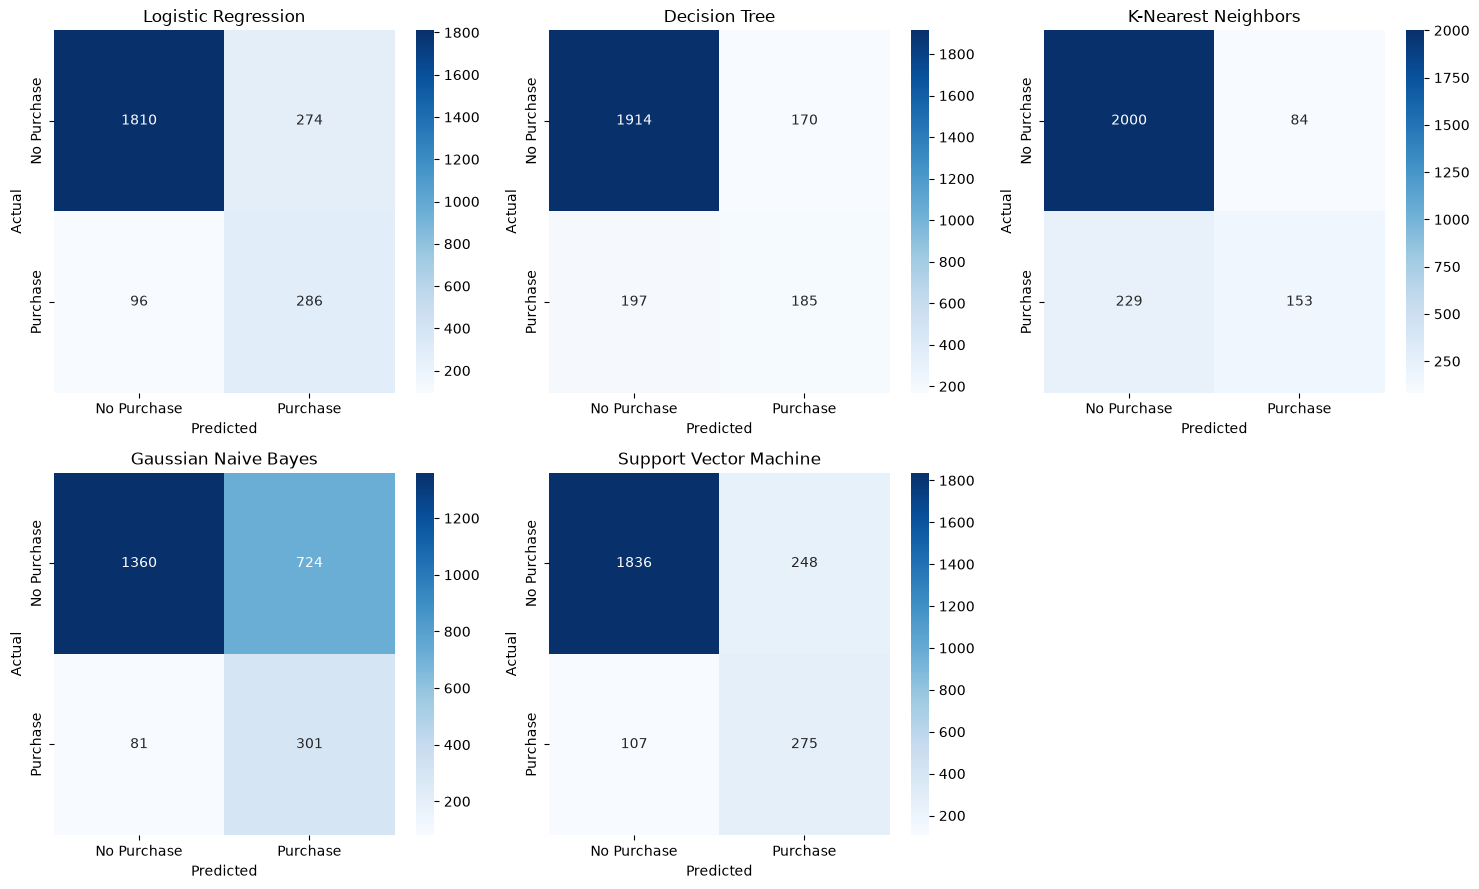

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (name, pipeline) in enumerate(trained_models.items()):
    y_pred = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=axes[i],
        xticklabels=["No Purchase", "Purchase"],
        yticklabels=["No Purchase", "Purchase"]
    )

    axes[i].set_title(name)
    axes[i].set_xlabel("Predicted")
    axes[i].set_ylabel("Actual")

axes[-1].axis("off")
plt.tight_layout()
plt.show()

In [20]:
for name, pipeline in trained_models.items():
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    y_pred = pipeline.predict(X_test)

    print(
        classification_report(
            y_test,
            y_pred,
            target_names=["No Purchase", "Purchase"],
            zero_division=0
        )
    )


Logistic Regression
              precision    recall  f1-score   support

 No Purchase       0.95      0.87      0.91      2084
    Purchase       0.51      0.75      0.61       382

    accuracy                           0.85      2466
   macro avg       0.73      0.81      0.76      2466
weighted avg       0.88      0.85      0.86      2466


Decision Tree
              precision    recall  f1-score   support

 No Purchase       0.91      0.92      0.91      2084
    Purchase       0.52      0.48      0.50       382

    accuracy                           0.85      2466
   macro avg       0.71      0.70      0.71      2466
weighted avg       0.85      0.85      0.85      2466


K-Nearest Neighbors
              precision    recall  f1-score   support

 No Purchase       0.90      0.96      0.93      2084
    Purchase       0.65      0.40      0.49       382

    accuracy                           0.87      2466
   macro avg       0.77      0.68      0.71      2466
weighted avg     

In [21]:
from pathlib import Path

model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "K-Nearest Neighbors": "knn.joblib",
    "Gaussian Naive Bayes": "gaussian_nb.joblib",
    "Support Vector Machine": "svm.joblib"
}

for name, pipeline in trained_models.items():
    path = model_dir / model_filenames[name]
    joblib.dump(pipeline, path)
    print(f"Saved {name}: {path}")

Saved Logistic Regression: model/logistic_regression.joblib
Saved Decision Tree: model/decision_tree.joblib
Saved K-Nearest Neighbors: model/knn.joblib
Saved Gaussian Naive Bayes: model/gaussian_nb.joblib
Saved Support Vector Machine: model/svm.joblib


In [22]:
results_df.to_csv("model_comparison_results.csv", index=False)

print("Results saved to model_comparison_results.csv")

Results saved to model_comparison_results.csv
